### Linear Growth

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate

#### Growing mode equation

In [2]:
import sys
sys.path.append('../scripts')
from exercise_1 import Cosmology

In [3]:
EdS_cosmo = Cosmology(Omega_m0=1.0, Omega_lambda0=0.0) #Einstein-de Sitter
flat_lambdaCDM_cosmo = Cosmology(Omega_m0=0.3, Omega_lambda0=0.7) #Flat ΛCDM
open_CDM_cosmo = Cosmology(Omega_m0=0.3, Omega_lambda0=0.0) #Open CDM
a = np.linspace(1e-2, 1.0, 500)

In [4]:
# ODE evaluation

D_eds, f_eds = EdS_cosmo.growing_mode(a) 
D_flCDM, f_flCDM = flat_lambdaCDM_cosmo.growing_mode(a) 
D_openCDM, f_openCDM = open_CDM_cosmo.growing_mode(a) 

print("EdS: max |D - a| =", np.max(np.abs(D_eds - a)))
print("EdS: max |f - 1| =", np.max(np.abs(f_eds - 1)))

# interval of a where D deviates significantly from a and f deviates significantly from 1
deviation_threshold = 0.01
flCDM_dev_indices = np.where((np.abs(D_flCDM - a) > deviation_threshold) | (np.abs(f_flCDM - 1) > deviation_threshold))[0]
openCDM_dev_indices = np.where((np.abs(D_openCDM - a) > deviation_threshold) | (np.abs(f_openCDM - 1) > deviation_threshold))[0]

print("Flat ΛCDM: above 0.01 deviation interval a =", a[flCDM_dev_indices[0]], "to", a[flCDM_dev_indices[-1]])
print("Open CDM: above 0.01 deviation interval a =", a[openCDM_dev_indices[0]], "to", a[openCDM_dev_indices[-1]])

EdS: max |D - a| = 1.3128576004106662e-10
EdS: max |f - 1| = 2.9976021664879227e-15
Flat ΛCDM: above 0.01 deviation interval a = 0.035791583166332665 to 1.0
Open CDM: above 0.01 deviation interval a = 0.01 to 1.0


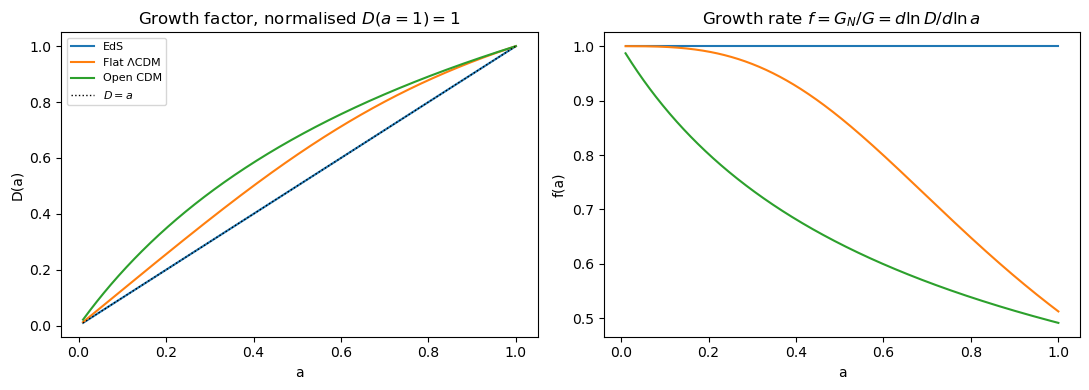

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for name, (D, f) in zip(["EdS", "Flat ΛCDM", "Open CDM"], [(D_eds, f_eds), (D_flCDM, f_flCDM), (D_openCDM, f_openCDM)]):
    ax[0].plot(a, D, label=name)
    ax[1].plot(a, f, label=name)

ax[0].plot(a, a, "k:", lw=1, label=r"$D=a$")
ax[0].set(xlabel="a", ylabel="D(a)", title=r"Growth factor, normalised $D(a=1)=1$")
ax[1].set(xlabel="a", ylabel="f(a)", title=r"Growth rate $f = G_N/G = d\ln D/d\ln a$")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()


In [9]:
# Quadrature evaluation
D_eds_quad, f_eds_quad = EdS_cosmo.growing_mode_quadrature(a)
D_flCDM_quad, f_flCDM_quad = flat_lambdaCDM_cosmo.growing_mode_quadrature(a)
D_openCDM_quad, f_openCDM_quad = open_CDM_cosmo.growing_mode_quadrature(a)

print("max |D_EdS (quadrature) - D_ODE| =", np.max(np.abs(D_eds_quad - D_eds)))
print("max |f_EdS (quadrature) - f_ODE| =", np.max(np.abs(f_eds_quad - f_eds)))
print("max |D_Flat ΛCDM (quadrature) - D_ODE| =", np.max(np.abs(D_flCDM_quad - D_flCDM)))
print("max |f_Flat ΛCDM (quadrature) - f_ODE| =", np.max(np.abs(f_flCDM_quad - f_flCDM)))
print("max |D_Open CDM (quadrature) - D_ODE| =", np.max(np.abs(D_openCDM_quad - D_openCDM)))
print("max |f_Open CDM (quadrature) - f_ODE| =", np.max(np.abs(f_openCDM_quad - f_openCDM)))


max |D_EdS (quadrature) - D_ODE| = 1.3128598208567155e-10
max |f_EdS (quadrature) - f_ODE| = 3.552713678800501e-15
max |D_Flat ΛCDM (quadrature) - D_ODE| = 1.2241596625273132e-10
max |f_Flat ΛCDM (quadrature) - f_ODE| = 3.0703484199534614e-10
max |D_Open CDM (quadrature) - D_ODE| = 3.720045209376632e-08
max |f_Open CDM (quadrature) - f_ODE| = 4.2633022584448454e-06


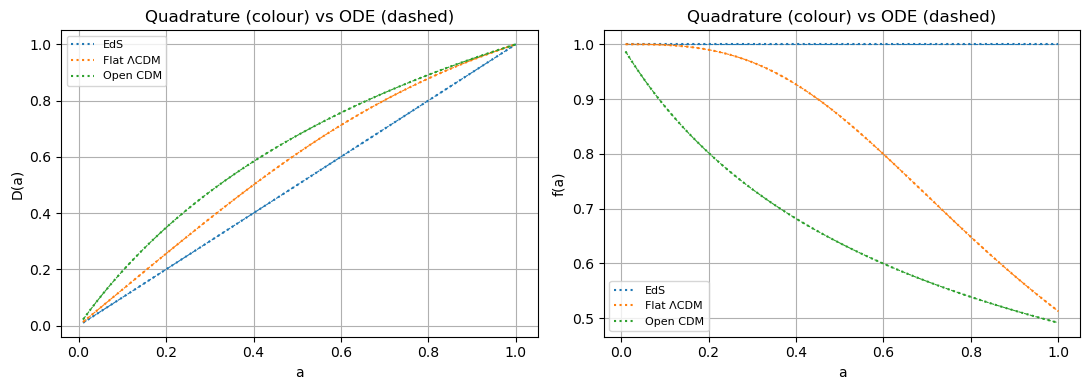

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for name, (D, D_q), (f, f_q), c in zip(["EdS", "Flat ΛCDM", "Open CDM"], [(D_eds, D_eds_quad), (D_flCDM, D_flCDM_quad), (D_openCDM, D_openCDM_quad)], [(f_eds, f_eds_quad), (f_flCDM, f_flCDM_quad), (f_openCDM, f_openCDM_quad)], ["tab:blue", "tab:orange", "tab:green"]):
    ax[0].plot(a, D, linestyle='dotted', label=name, color=c)
    ax[0].plot(a, D_q, "--", lw=0.8, color=c)
    ax[1].plot(a, f, linestyle='dotted', label=name, color=c)
    ax[1].plot(a, f_q, "--", lw=0.8, color=c)
ax[0].set(xlabel="a", ylabel="D(a)", title="Quadrature (colour) vs ODE (dashed)")
ax[0].grid(True)
ax[0].legend(fontsize=8)
ax[1].set(xlabel="a", ylabel="f(a)", title="Quadrature (colour) vs ODE (dashed)")
ax[1].grid(True)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


#### Errors: initial-mode variations and solver choice

In [21]:
a = np.linspace(0.05, 1.0, 200)            # keep a >= every a_i used below
err = lambda x, y: np.max(np.abs(x - y))

# a_i variation
a_is = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
print('ai errors:')
for name, cosmo in zip(["EdS", "Flat ΛCDM", "Open CDM"], [EdS_cosmo, flat_lambdaCDM_cosmo, open_CDM_cosmo]):
    D_ex, f_ex = cosmo.growing_mode_quadrature(a)
    errD, errf = [], []
    for ai in a_is:
        D, f = cosmo.growing_mode(a, a_i=ai, rtol=1e-12, atol=1e-20)
        errD.append(err(D, D_ex))
        errf.append(err(f, f_ex))
    print(f"{name} \n a_i={a_is[0]:.0e} max|ΔD|={errD[0]:.2e}  max|Δf|={errf[0]:.2e}"
            f"\n a_i={a_is[2]:.0e} max|ΔD|={errD[2]:.2e}  max|Δf|={errf[2]:.2e}"
            f"\n a_i={a_is[3]:.0e} max|ΔD|={errD[3]:.2e}  max|Δf|={errf[3]:.2e}"
            f"\n a_i={a_is[4]:.0e} max|ΔD|={errD[4]:.2e}  max|Δf|={errf[4]:.2e}")

# tolerance variation
print('tol errors:')
tols = [1e-3, 1e-5, 1e-7, 1e-9, 1e-11]
for name, cosmo in zip(["EdS", "Flat ΛCDM", "Open CDM"], [EdS_cosmo, flat_lambdaCDM_cosmo, open_CDM_cosmo]):
    D_ex, f_ex = cosmo.growing_mode_quadrature(a)
    D_ref, f_ref = cosmo.growing_mode(a, a_i=1e-3, rtol=1e-13, atol=1e-20)
    errD, errf = [], []
    for tol in tols:
        D, f = cosmo.growing_mode(a, a_i=1e-3, rtol=tol, atol=1e-4*tol)
        errD.append(err(D, D_ex))
        errf.append(err(f, f_ex))
    print(f"tol errors: \n {name} \n tol={tols[0]:.0e} max|ΔD|={errD[0]:.2e}  max|Δf|={errf[0]:.2e}"
            f"\n tol={tols[1]:.0e} max|ΔD|={errD[1]:.2e}  max|Δf|={errf[1]:.2e}"
            f"\n tol={tols[2]:.0e} max|ΔD|={errD[2]:.2e}  max|Δf|={errf[2]:.2e}"
            f"\n tol={tols[3]:.0e} max|ΔD|={errD[3]:.2e}  max|Δf|={errf[3]:.2e}"
            f"\n tol={tols[4]:.0e} max|ΔD|={errD[4]:.2e}  max|Δf|={errf[4]:.2e}")


ai errors:
EdS 
 a_i=1e-02 max|ΔD|=1.35e-12  max|Δf|=2.66e-15
 a_i=1e-04 max|ΔD|=1.37e-12  max|Δf|=2.89e-15
 a_i=1e-05 max|ΔD|=1.24e-12  max|Δf|=3.33e-15
 a_i=1e-06 max|ΔD|=1.36e-12  max|Δf|=2.66e-15
Flat ΛCDM 
 a_i=1e-02 max|ΔD|=5.84e-10  max|Δf|=2.28e-08
 a_i=1e-04 max|ΔD|=2.84e-12  max|Δf|=6.72e-12
 a_i=1e-05 max|ΔD|=3.78e-12  max|Δf|=8.67e-12
 a_i=1e-06 max|ΔD|=3.45e-12  max|Δf|=8.01e-12
Open CDM 
 a_i=1e-02 max|ΔD|=1.06e-05  max|Δf|=2.47e-04
 a_i=1e-04 max|ΔD|=1.09e-12  max|Δf|=2.56e-11
 a_i=1e-05 max|ΔD|=6.71e-13  max|Δf|=6.89e-12
 a_i=1e-06 max|ΔD|=8.96e-13  max|Δf|=1.01e-11
tol errors:
tol errors: 
 EdS 
 tol=1e-03 max|ΔD|=1.17e-03  max|Δf|=1.15e-12
 tol=1e-05 max|ΔD|=3.62e-05  max|Δf|=1.11e-14
 tol=1e-07 max|ΔD|=9.80e-08  max|Δf|=4.22e-15
 tol=1e-09 max|ΔD|=1.65e-09  max|Δf|=3.33e-15
 tol=1e-11 max|ΔD|=1.20e-11  max|Δf|=3.33e-15
tol errors: 
 Flat ΛCDM 
 tol=1e-03 max|ΔD|=1.50e-04  max|Δf|=5.03e-04
 tol=1e-05 max|ΔD|=1.40e-06  max|Δf|=1.25e-04
 tol=1e-07 max|ΔD|=8.62e-08  max|